# Week 1 · Task 4 — Pick the right chart, five times

Each chart is followed by a written interpretation. The notebook uses paths relative to the repository, not a machine-specific drive.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def assignment_data(filename):
    candidates = (
        Path.cwd() / "week1" / "assignments" / "data" / filename,
        Path.cwd() / "assignments" / "data" / filename,
    )
    for candidate in candidates:
        if candidate.is_file():
            return candidate
    searched = "\n".join(str(path) for path in candidates)
    raise FileNotFoundError(f"Could not find {filename}. Searched:\n{searched}")

df = pd.read_csv(assignment_data("mpg.csv"))
missing_horsepower = int(df["horsepower"].isna().sum())
print(f"Source rows: {len(df)}")
print(f"Missing horsepower values: {missing_horsepower}")
print("Horsepower is not used in the five questions below, so those rows are retained.")


Source rows: 398
Missing horsepower values: 6
Horsepower is not used in the five questions below, so those rows are retained.


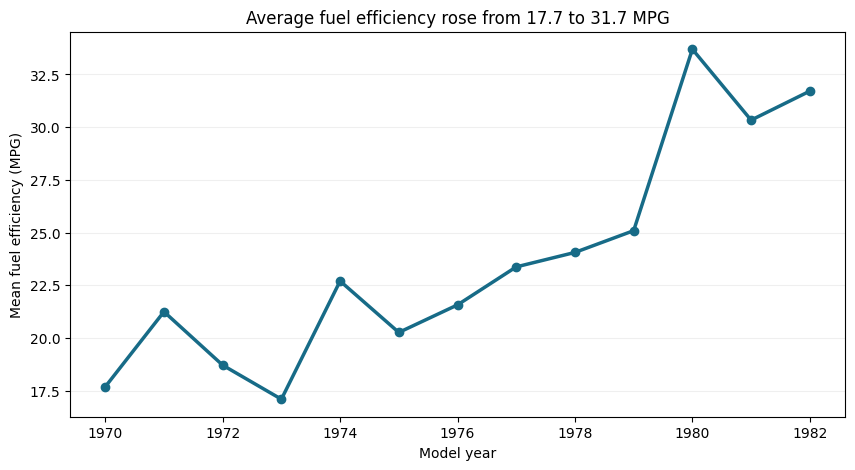

In [2]:

mpg_by_year = df.groupby("model_year", as_index=False)["mpg"].mean()
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(mpg_by_year["model_year"] + 1900, mpg_by_year["mpg"], marker="o", color="#176B87", linewidth=2.5)
ax.set_title("Average fuel efficiency rose from 17.7 to 31.7 MPG")
ax.set_xlabel("Model year")
ax.set_ylabel("Mean fuel efficiency (MPG)")
ax.grid(axis="y", alpha=0.2)
plt.show()


### 1 · Did cars get more fuel-efficient?

A line chart fits an ordered year trend. Mean MPG rises from about 17.7 in model year 1970 to about 31.7 in 1982. The calculation uses every row with MPG and model year; missing horsepower does not affect it.


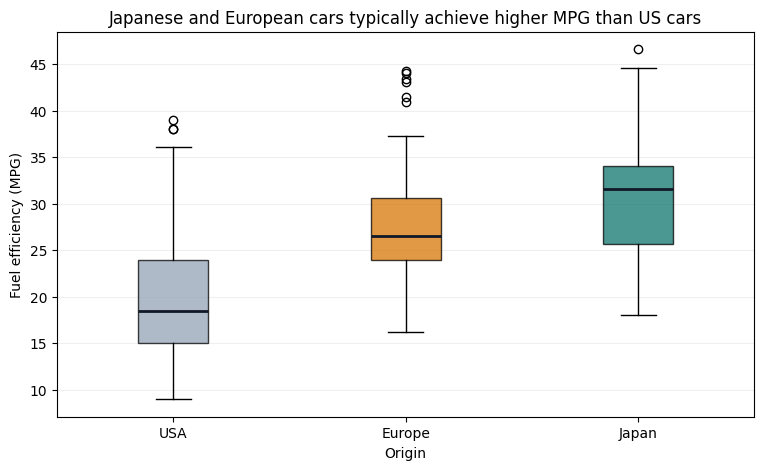

In [3]:

origin_order = ["usa", "europe", "japan"]
origin_names = {"usa": "USA", "europe": "Europe", "japan": "Japan"}
fig, ax = plt.subplots(figsize=(9, 5))
groups = [
    df.loc[df["origin"] == origin, "mpg"].dropna().to_numpy()
    for origin in origin_order
]
labels = [origin_names[origin] for origin in origin_order]
ax.boxplot(groups, tick_labels=labels, patch_artist=True, medianprops={"color": "#111827", "linewidth": 2})
for patch, color in zip(ax.patches, ["#94A3B8", "#D97706", "#0F766E"]):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)
ax.set_title("Japanese and European cars typically achieve higher MPG than US cars")
ax.set_xlabel("Origin")
ax.set_ylabel("Fuel efficiency (MPG)")
ax.grid(axis="y", alpha=0.2)
plt.show()


### 2 · Do origins differ in fuel efficiency?

A box plot compares the distributions, medians, and spread of MPG across the three origin groups. Japanese and European cars generally have higher MPG distributions than US cars, though distributions overlap. A distribution chart is more informative than comparing means alone.


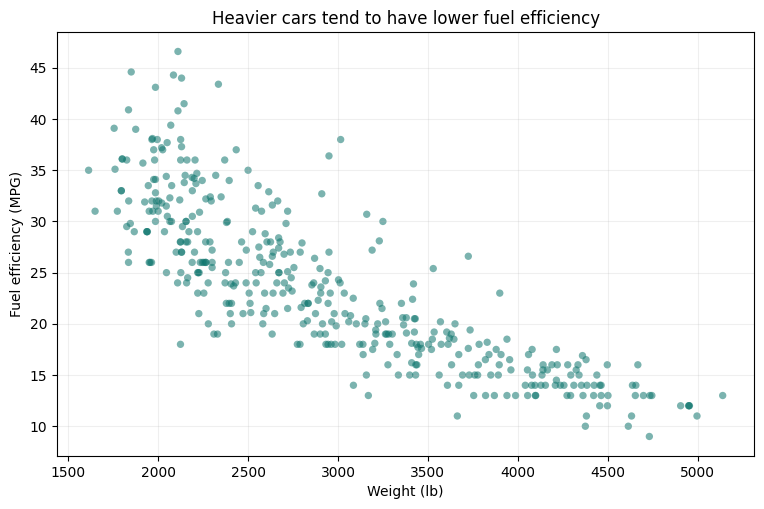

In [4]:

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(df["weight"], df["mpg"], alpha=0.55, s=28, color="#0F766E", edgecolors="none")
ax.set_title("Heavier cars tend to have lower fuel efficiency")
ax.set_xlabel("Weight (lb)")
ax.set_ylabel("Fuel efficiency (MPG)")
ax.grid(alpha=0.2)
plt.show()


### 3 · How are weight and fuel efficiency related?

A scatter plot is appropriate for two quantitative variables. The clear downward association indicates that heavier cars tend to have lower MPG. The plot shows association, not proof that weight alone causes the difference.


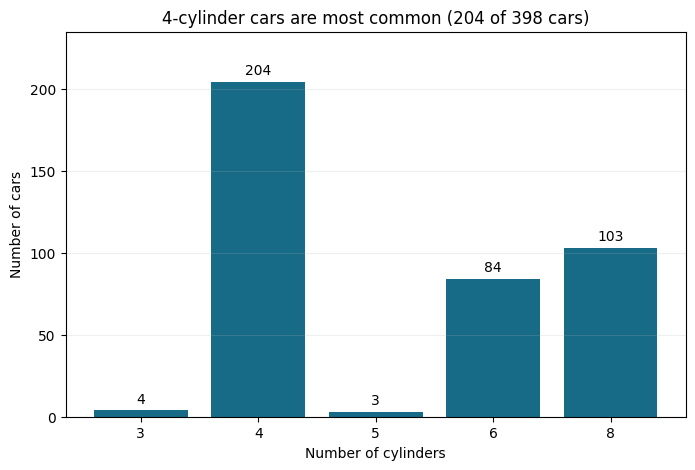

In [5]:

cylinder_counts = df["cylinders"].value_counts().sort_index()
most_common_cylinders = int(cylinder_counts.idxmax())
most_common_count = int(cylinder_counts.max())
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(cylinder_counts.index.astype(str), cylinder_counts.values, color="#176B87")
ax.bar_label(bars, padding=3)
ax.set_title(
    f"{most_common_cylinders}-cylinder cars are most common "
    f"({most_common_count} of {len(df)} cars)"
)
ax.set_xlabel("Number of cylinders")
ax.set_ylabel("Number of cars")
ax.set_ylim(0, cylinder_counts.max() * 1.15)
ax.grid(axis="y", alpha=0.2)
plt.show()


### 4 · How are cylinder counts distributed?

A bar chart compares counts for the discrete cylinder categories. Eight-cylinder cars are the largest group in this dataset; the bar labels make the sample counts explicit.


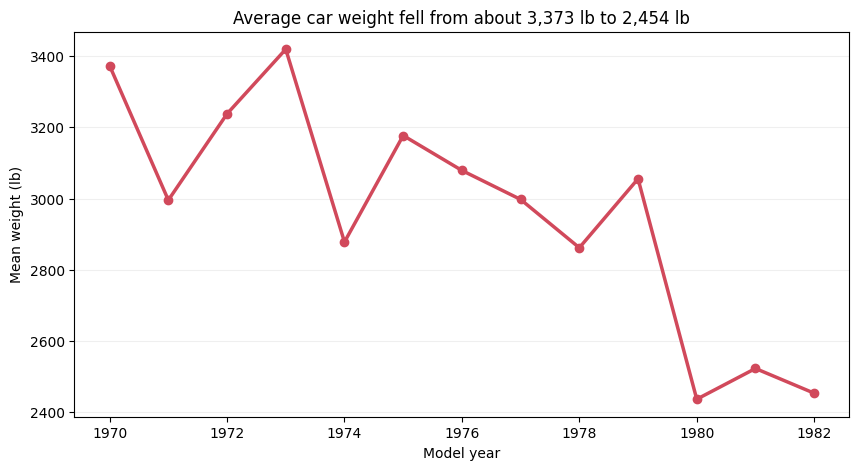

In [6]:

weight_by_year = df.groupby("model_year", as_index=False)["weight"].mean()
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(weight_by_year["model_year"] + 1900, weight_by_year["weight"], marker="o", color="#D1495B", linewidth=2.5)
ax.set_title("Average car weight fell from about 3,373 lb to 2,454 lb")
ax.set_xlabel("Model year")
ax.set_ylabel("Mean weight (lb)")
ax.grid(axis="y", alpha=0.2)
plt.show()


### 5 · Did cars get lighter?

Yes, the yearly mean weight drops from approximately 3,373 lb in 1970 to 2,454 lb in 1982. Together with the MPG trend and weight-MPG scatter, this is consistent with lighter cars contributing to better fuel efficiency. The charts alone do not establish how much of the MPG improvement is caused by weight rather than engine, technology, or fleet composition.


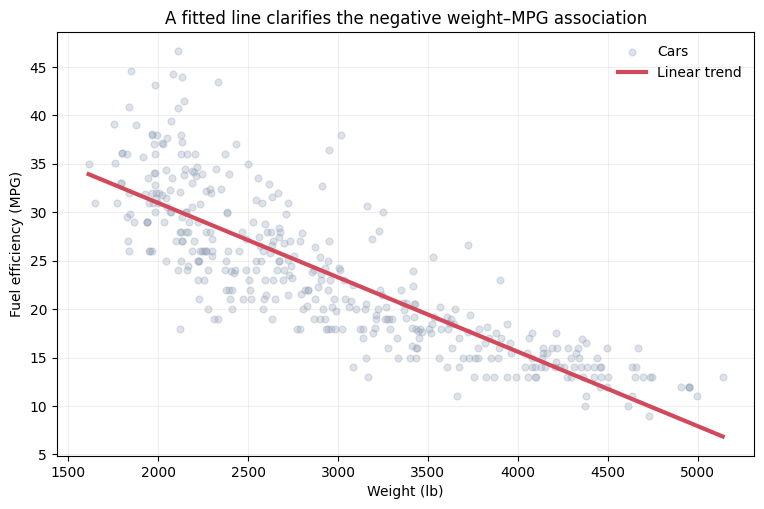

In [7]:

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(df["weight"], df["mpg"], alpha=0.3, s=24, color="#94A3B8", label="Cars")
slope, intercept = np.polyfit(df["weight"], df["mpg"], 1)
x_line = np.linspace(df["weight"].min(), df["weight"].max(), 100)
ax.plot(x_line, slope * x_line + intercept, color="#D1495B", linewidth=3, label="Linear trend")
ax.set_title("A fitted line clarifies the negative weight–MPG association")
ax.set_xlabel("Weight (lb)")
ax.set_ylabel("Fuel efficiency (MPG)")
ax.legend(frameon=False)
ax.grid(alpha=0.2)
plt.show()


### Redrawing the weakest chart

The original weight-versus-MPG scatter can look busy because many points overlap. This redraw uses lighter points and a clearly labeled linear trend line. It improves the visibility of the overall direction but does not imply a causal model or capture every nonlinear pattern.

All five questions use the available rows for their own fields. Six rows have missing horsepower, but horsepower is not part of these five calculations, so those rows are retained rather than dropped. The dashboard titles state the findings instead of repeating axis names.
